<div align="center">
<h1>Visualisasi Domain: 3 Negara + Indo di Ruang Fitur YOLO</h1>
<p>Embedding 256-d dari YOLOv8n terlatih-sumber (model.embed, lapisan kedua-terakhir) + proyeksi t-SNE/UMAP + statistik citra. Full data test per domain: China 180, Japan 705, India 110, Indo 308 (1303 citra, tanpa subsampling).</p>
</div>

In [11]:
import random
from pathlib import Path
import pandas as pd

REPO = next((q for q in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (q / 'data' / 'RDD-indo-v2').exists()), Path.cwd().resolve())
print('REPO:', REPO)
SRC_TEST = REPO / 'data/NRDD-2024/RDD_Split_Final_china_japan_india_6_classes/RDD_Split_Final_china_japan_india_6_classes/test/images'
INDO_TEST = REPO / 'data/RDD-indo-v2/test/images'
OUT = REPO / 'runs/rdd_yolov8n_local/evaluation/domain_viz'
OUT.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = random.Random(SEED)
rows = []
for dom, pref in [('China', 'China_'), ('Japan', 'Japan_'), ('India', 'India_')]:
    pool = sorted(SRC_TEST.glob(pref + '*'))
    print(dom, 'pool:', len(pool))
    rows += [{'path': str(p), 'domain': dom} for p in pool]
pool = sorted(INDO_TEST.glob('*'))
print('Indo pool:', len(pool))
rows += [{'path': str(p), 'domain': 'Indo'} for p in pool]
rng.shuffle(rows)
man = pd.DataFrame(rows)
man.to_csv(OUT / 'manifest.csv', index=False)
print(f'total: {len(man)}')
print(man['domain'].value_counts().to_string())
print('tersimpan:', OUT / 'manifest.csv')


REPO: /mnt/Data/01_Akademik/TA-Project
China pool: 180
Japan pool: 705
India pool: 110
Indo pool: 308
total: 1303
domain
Japan    705
Indo     308
China    180
India    110
tersimpan: /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/evaluation/domain_viz/manifest.csv


## ***Embedding Model***
---
Vektor 256-d per citra dari backbone YOLOv8n yang dilatih di sumber: yang model baca, bukan fitur generik.

In [12]:
import time
import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

man = pd.read_csv(OUT / 'manifest.csv')
W = REPO / 'runs/rdd_yolov8n_local/experiments/yolov8n_class_weight/weights/best.pt'
m = YOLO(str(W))
dev = 0 if torch.cuda.is_available() else 'cpu'
print('device:', dev, '| citra:', len(man))
vecs, t0 = [], time.time()
with torch.no_grad():
    for i in range(0, len(man), 16):
        batch = man['path'].tolist()[i:i + 16]
        vecs += [e.cpu().numpy() for e in m.embed(batch, verbose=False)]
X = np.stack(vecs).astype(np.float32)
np.save(OUT / 'embeddings.npy', X)
np.save(OUT / 'domains.npy', man['domain'].to_numpy())
print(f'X={X.shape} waktu={time.time() - t0:.1f}s tersimpan: embeddings.npy')

device: 0 | citra: 1303
X=(1303, 256) waktu=12.6s tersimpan: embeddings.npy


## ***Proyeksi 2D (t-SNE dan UMAP)***
---
Dua metode komplementer: t-SNE untuk struktur lokal, UMAP untuk keseimbangan lokal-global. Warna konsisten antar plot.

silhouette (ruang 256-d): 0.200


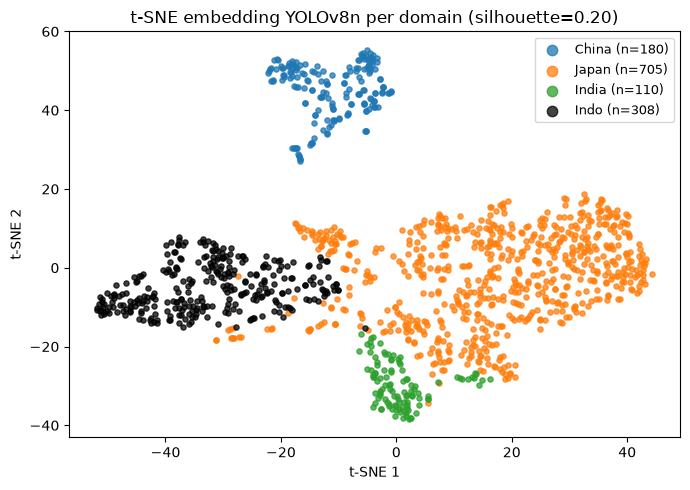

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score

X = np.load(OUT / 'embeddings.npy')
dom = np.load(OUT / 'domains.npy', allow_pickle=True)
order = ['China', 'Japan', 'India', 'Indo']
cmap = {'China': '#1f77b4', 'Japan': '#ff7f0e', 'India': '#2ca02c', 'Indo': '#030303ff'}
Xn = normalize(X)
Z = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto').fit_transform(Xn)
sil = silhouette_score(Xn, dom)
print(f'silhouette (ruang 256-d): {sil:.3f}')
plt.figure(figsize=(7, 5))
for d in order:
    pts = Z[dom == d]
    plt.scatter(pts[:, 0], pts[:, 1], s=14, alpha=0.75, c=cmap[d], label=f'{d} (n={(dom == d).sum()})')
plt.legend(markerscale=2, fontsize=9)
plt.title(f't-SNE embedding YOLOv8n per domain (silhouette={sil:.2f})')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.tight_layout()
plt.savefig(str(OUT / 'tsne.png'), dpi=120)
plt.show()

/home/varys/.local/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


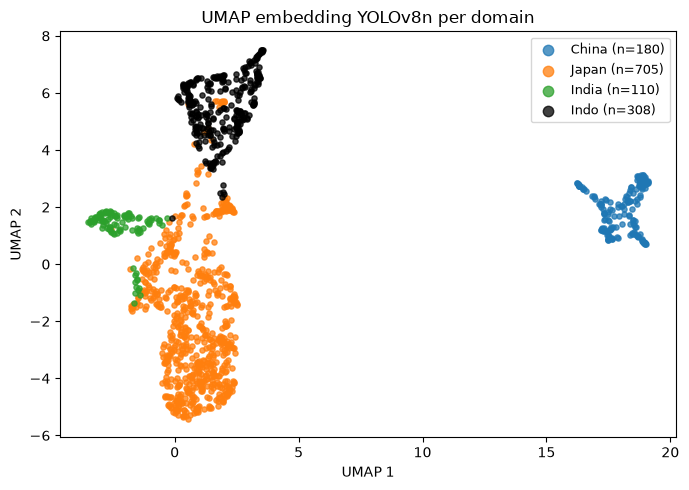

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.preprocessing import normalize

X = np.load(OUT / 'embeddings.npy')
dom = np.load(OUT / 'domains.npy', allow_pickle=True)
order = ['China', 'Japan', 'India', 'Indo']
cmap = {'China': '#1f77b4', 'Japan': '#ff7f0e', 'India': '#2ca02c', 'Indo': '#000000ff'}
U = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(normalize(X))
plt.figure(figsize=(7, 5))
for d in order:
    pts = U[dom == d]
    plt.scatter(pts[:, 0], pts[:, 1], s=14, alpha=0.75, c=cmap[d], label=f'{d} (n={(dom == d).sum()})')
plt.legend(markerscale=2, fontsize=9)
plt.title('UMAP embedding YOLOv8n per domain')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.tight_layout()
plt.savefig(str(OUT / 'umap.png'), dpi=120)
plt.show()

## ***Statistik Citra Per-Domain***
---
Empat ukuran murah yang bisa dijelaskan ke reviewer: kecerahan, saturasi, kontras, ketajaman.

        brightness  saturation  contrast  sharpness
domain                                             
China        154.8         7.3      26.8     2296.8
India        144.0        35.3      64.4      181.4
Indo         160.3        15.1      37.1      532.6
Japan        119.4        44.6      70.3     1430.9


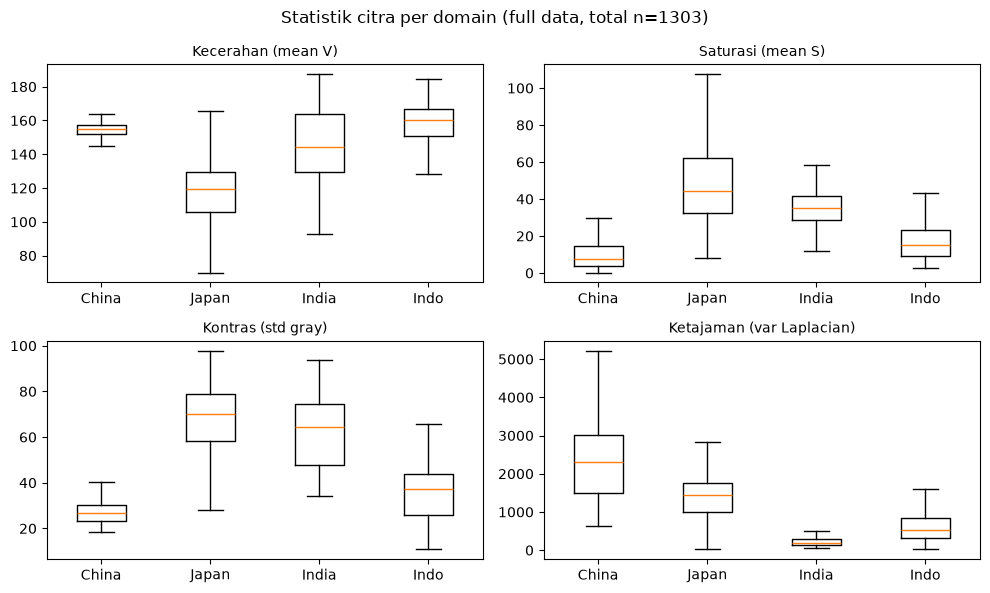

In [5]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt

man = pd.read_csv(OUT / 'manifest.csv')
recs = []
for r in man.itertuples():
    im = cv2.imread(r.path)
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    recs.append({'domain': r.domain,
                  'brightness': float(hsv[:, :, 2].mean()),
                  'saturation': float(hsv[:, :, 1].mean()),
                  'contrast': float(gray.std()),
                  'sharpness': float(cv2.Laplacian(gray, cv2.CV_64F).var())})
st = pd.DataFrame(recs)
st.to_csv(OUT / 'image_stats.csv', index=False)
print(st.groupby('domain').median().round(1).to_string())
order = ['China', 'Japan', 'India', 'Indo']
fig, ax = plt.subplots(2, 2, figsize=(10, 6))
for a, col, ttl in zip(ax.flat, ['brightness', 'saturation', 'contrast', 'sharpness'],
                         ['Kecerahan (mean V)', 'Saturasi (mean S)', 'Kontras (std gray)', 'Ketajaman (var Laplacian)']):
    a.boxplot([st.loc[st.domain == d, col] for d in order], showfliers=False)
    a.set_xticklabels(order)
    a.set_title(ttl, fontsize=10)
plt.suptitle(f'Statistik citra per domain (full data, total n={len(st)})')
plt.tight_layout()
plt.savefig(str(OUT / 'stats.png'), dpi=120)
plt.show()

### ***Contoh Citra Per-Domain***
Empat citra pertama tiap domain dari sampel yang sama, untuk grounding kualitatif.

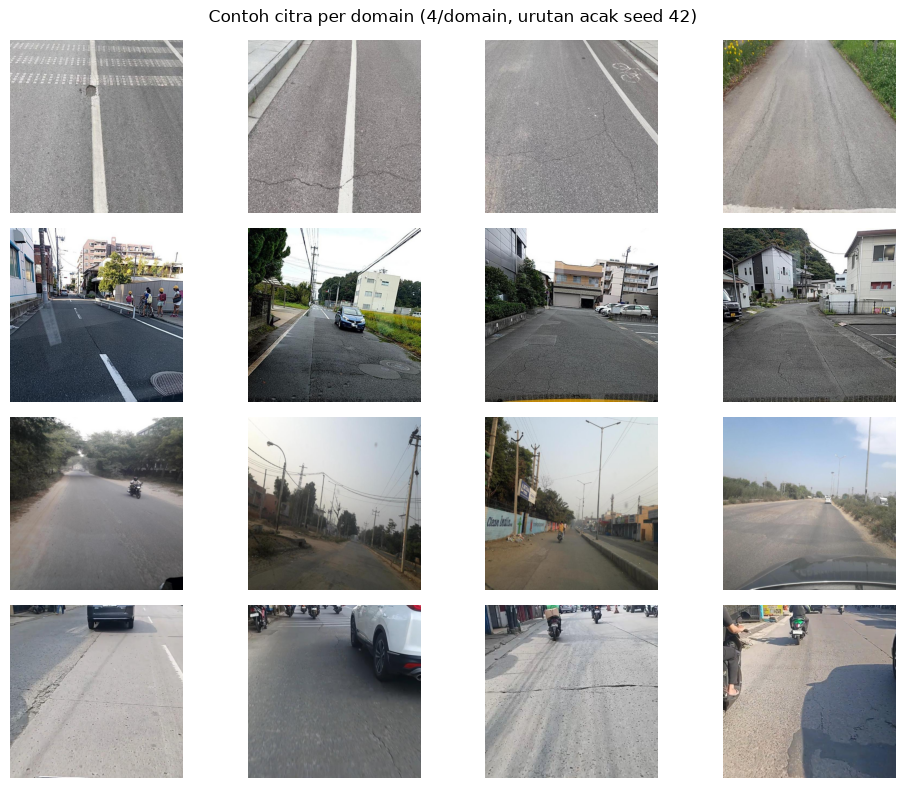

In [6]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt

man = pd.read_csv(OUT / 'manifest.csv')
order = ['China', 'Japan', 'India', 'Indo']
fig, ax = plt.subplots(4, 4, figsize=(10, 8))
for i, d in enumerate(order):
    paths = man.loc[man.domain == d, 'path'].tolist()[:4]
    for j, p in enumerate(paths):
        a = ax[i][j]
        a.imshow(cv2.imread(p)[:, :, ::-1])
        a.axis('off')
        if j == 0:
            a.set_ylabel(d, fontsize=11, rotation=0, labelpad=25, va='center')
plt.suptitle('Contoh citra per domain (4/domain, urutan acak seed 42)')
plt.tight_layout()
plt.savefig(str(OUT / 'samples.png'), dpi=120)
plt.show()

## ***Kesimpulan Sementara***
---
Full data (1303 citra, silhouette 0.20) mengonfirmasi temuan versi sampel: China terisolasi di kedua plot; Indo klaster sendiri (kiri di t-SNE, atas di UMAP) dengan sedikit overlap tepi ke Japan; India klaster kecil rapat menempel massa Japan yang dominan (n=705). Median statistik nyaris identik dengan versi sampel, sehingga pola robust dan bukan artefak sampling. Penurunan silhouette (0.26 ke 0.20) wajar akibat imbalance Japan. Catatan baca: t-SNE/UMAP untuk identifikasi klaster, bukan jarak antar-klaster.